# Issued prices and future dates

Read an immutable operational batch and match its estimates to observed reports and supported horizons.

In [1]:
import sys
from pathlib import Path

HERE = Path.cwd().resolve()
NB = HERE if (HERE / 'mandi_notes.py').is_file() else HERE / 'Notebook'
sys.path.insert(0, str(NB))
from mandi_notes import *

In [2]:
snap = publication()
batch = snap["batch"]
estimates = predictions(snap)
print("Batch issued:", batch["issue"], "· Target date:", batch["target_date"])
from Code.daily.policy import MIN_OBSERVATIONS, MIN_SPAN_DAYS, MIN_RECENT_OBSERVATIONS, MIN_DENSITY, MAX_AGE_DAYS
display(pd.Series({"minimum observations": MIN_OBSERVATIONS, "minimum span (days)": MIN_SPAN_DAYS,
    "minimum recent observations": MIN_RECENT_OBSERVATIONS, "minimum recent density": MIN_DENSITY,
    "maximum report age (days)": MAX_AGE_DAYS}, name="Daily eligibility").to_frame())
examples = estimates.loc[estimates.observed_today.notna(),
    ["crop","market","last_observation_date","observed_today","predicted_modal_price"]]
if len(examples):
    display(examples.head(6))
else:
    print("This issue has no same-day actuals among eligible forecasts.")
    display(estimates[["crop","market","last_observation_date","last_observed_price","predicted_modal_price"]].head(5))

Batch issued: 2026-11-13T21:28:46.252788+05:30 · Target date: 2026-11-13


,Daily eligibility
minimum observations,180.00
minimum span (days),365.00
minimum recent observations,60.00
minimum recent density,0.25
maximum report age (days),7.00


This issue has no same-day actuals among eligible forecasts.


,crop,market,last_observation_date,last_observed_price,predicted_modal_price
0,Green Chilli,Lalbagh APMC,2026-11-11,5000.0,5000.0
1,Green Chilli,Medinipur(West) APMC,2026-11-12,6100.0,6100.0
2,Green Chilli,Warangal APMC,2026-11-12,2750.0,2750.0
3,Green Chilli,Bowenpally APMC,2026-11-12,3500.0,3500.0
4,Green Chilli,Siliguri APMC,2026-11-12,4200.0,4200.0


,market,state,forecast_issue_timestamp,target_date,price,historical_mae,model
0,Lalbagh APMC,West Bengal,2026-11-13T21:28:46.252788+05:30,2026-11-20,5000.0,463.54,persistence
1,Medinipur(West) APMC,West Bengal,2026-11-13T21:28:46.252788+05:30,2026-11-20,6100.0,463.54,persistence
2,Warangal APMC,Telangana,2026-11-13T21:28:46.252788+05:30,2026-11-20,2750.0,463.54,persistence
3,Bowenpally APMC,Telangana,2026-11-13T21:28:46.252788+05:30,2026-11-20,3500.0,463.54,persistence
4,Siliguri APMC,West Bengal,2026-11-13T21:28:46.252788+05:30,2026-11-20,4200.0,463.54,persistence
5,Sealdah Koley Market APMC,West Bengal,2026-11-13T21:28:46.252788+05:30,2026-11-20,6000.0,463.54,persistence


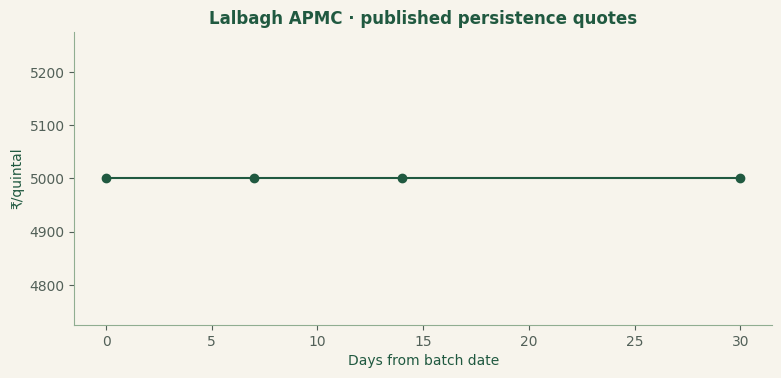

interactive(children=(Dropdown(description='Crop', options=('Green Chilli', 'Onion', 'Potato', 'Tomato', 'Whea…

In [3]:
future_batch = read_json(INTEL / "phase3/future_batch.json")
if future_batch["batch_signature"] == snap["batch_pointer_sha256"]:
    quotes = pd.DataFrame(future_batch["forecasts"])
    crops = sorted(quotes.crop.unique())
    def inspect(crop, horizon):
        selected = quotes[(quotes.crop == crop) & (quotes.horizon_days == horizon)]
        keys = ["series_id","market","state","forecast_issue_timestamp","predicted_modal_price"]
        merged = selected.merge(estimates[keys], on="series_id")
        display(merged[["market","state","forecast_issue_timestamp","target_date","price","historical_mae","model"]].head(6).round(2))
        row = merged.iloc[0]
        curve = quotes[quotes.series_id == row.series_id].sort_values("horizon_days")
        fig, ax = plt.subplots()
        ax.plot([0, *curve.horizon_days], [row.predicted_modal_price, *curve.price], "o-")
        ax.set(title=row.market+" · published persistence quotes", xlabel="Days from batch date", ylabel="₹/quintal")
        plt.show()
    controls(inspect, crop=crops, horizon=[7,14,30])
else:
    print("The saved future quotes and current publication have different batch signatures.")
    display(pd.read_csv(INTEL / "phase3/future_v1/metrics.csv").query("model == 'persistence'").head(6))

The production model publishes persistence. The separate 7, 14 and 30 day evaluation used 2017–2018 revised-archive data and an assumed reporting delay. Exact-horizon evidence is limited, and historical MAE is an error measure rather than a calibrated interval.

**Takeaway** · Persistence supplies a level estimate. Horizon MAE describes historical errors under the study protocol.

**Next** · Convert forecast prices into trade economics in Notebook 10.